In [1]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA 1: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc.

### Imagen ideal

#### HoughCircles

Diametro(mm): 25.75 mm, Diametro(px): 208.00 px, valor: 2.00 EUR, error: 0.000
Diametro(mm): 22.53 mm, Diametro(px): 182.00 px, valor: 0.20 EUR, error: 0.281
Diametro(mm): 22.28 mm, Diametro(px): 180.00 px, valor: 0.20 EUR, error: 0.034
Diametro(mm): 21.54 mm, Diametro(px): 174.00 px, valor: 0.05 EUR, error: 0.291
Diametro(mm): 20.06 mm, Diametro(px): 162.00 px, valor: 0.10 EUR, error: 0.305
Diametro(mm): 19.06 mm, Diametro(px): 154.00 px, valor: 0.02 EUR, error: 0.315
Diametro(mm): 18.57 mm, Diametro(px): 150.00 px, valor: 0.02 EUR, error: 0.180
Diametro(mm): 16.34 mm, Diametro(px): 132.00 px, valor: 0.01 EUR, error: 0.091
Se han encontrado 8 monedas
Valor total de las monedas: 2.60 €


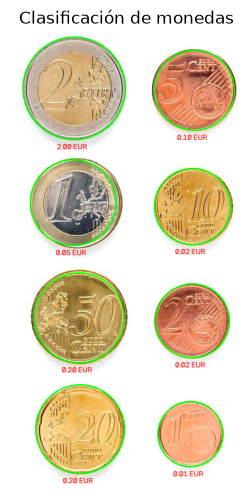

In [19]:
# Cargar imagen en RGB
img = cv2.imread('Monedas.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Conversión a gris
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suavizado de imagen eliminando altas frecuencias
grey_filter = cv2.medianBlur(grey, 7)

# Detección de círculos
circles = cv2.HoughCircles(
    grey_filter,  # imagen 
    cv2.HOUGH_GRADIENT,  # tipo de detección
    1,
    100,  # distancia mínima entre círculos
    param1=100, # valor del gradiente
    param2=50, # umbral acumulador
    minRadius=50,  # radio mínimo
    maxRadius=150,  # radio máximo
)

circles = np.round(circles[0]).astype(int)

# Diccionario de monedas euro con su diametro en mm
coins = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75
}

values = np.array(list(coins.keys()))
diameters = np.array(list(coins.values()))

# Calibracion de mm/px en base a la moneda de 2€ (la de mayor diámetro)
r_max = max(r for x, y, r in circles)
ratio = coins[2.00] / (2 * r_max)

# Clasificación de monedas encotradas
img_result = img_rgb.copy()
total = 0
total_value = 0.0

for x, y, r in circles:
    # Convertir diámetro de px a mm
    px_diameter = 2 * r
    mm_diameter = px_diameter * ratio

    # Modena cuyo valor del diámetro real esta más próximo
    diffs = np.abs(diameters - mm_diameter)
    index = np.argmin(diffs)

    # Error de la diferencia
    error = diffs[index]

    # Se recupera el valor en euros y suma al total
    value = values[index]
    total_value += value

    # Se añade una a las monedas encontradas
    total += 1

    # Se señala la moneda en la imagen
    cv2.circle(img_result, (x, y), r, (0, 255, 0), 2)

    # Etiqueta de la moneda
    label = f"{value:.2f} EUR"
    cv2.putText(img_result, label, (x - 35, y + r + 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)

    # Se imprime la información de la moneda por pantalla
    print(f"Diametro(mm): {mm_diameter:.2f} mm, Diametro(px): {px_diameter:.2f} px, valor: {value:.2f} EUR, error: {error:.3f}")

# Se imprime el número de monedas y el valor total
print(f"Se han encontrado {total} monedas")
print(f"Valor total de las monedas: {total_value:.2f} €")


# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(img_result)
plt.title("Clasificación de monedas")
plt.axis("off")
plt.show()


#### FindContours

Diametro(mm): 15.84 mm, Diametro(px): 127.63 px, valor: 0.01 EUR, error: 0.409
Diametro(mm): 18.74 mm, Diametro(px): 150.96 px, valor: 0.02 EUR, error: 0.012
Diametro(mm): 19.49 mm, Diametro(px): 157.05 px, valor: 0.10 EUR, error: 0.256
Diametro(mm): 20.69 mm, Diametro(px): 166.70 px, valor: 0.05 EUR, error: 0.558
Diametro(mm): 21.98 mm, Diametro(px): 177.05 px, valor: 0.20 EUR, error: 0.274
Diametro(mm): 22.75 mm, Diametro(px): 183.30 px, valor: 1.00 EUR, error: 0.498
Diametro(mm): 23.94 mm, Diametro(px): 192.85 px, valor: 0.50 EUR, error: 0.313
Diametro(mm): 25.75 mm, Diametro(px): 207.45 px, valor: 2.00 EUR, error: 0.000
Se han encontrado 8 monedas
Valor total de las monedas: 3.88 €


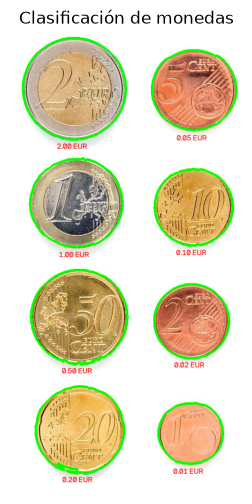

In [20]:
# Cargar imagen en RGB
img = cv2.imread('Monedas.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Conversión a gris
grey = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Suavizado de imagen eliminando altas frecuencias
grey_filter = cv2.medianBlur(grey, 7)

# Umbralizado con método de Otsu 
_, img_umb = cv2.threshold(grey_filter, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Detección de contornos externos
contours, _ = cv2.findContours(
    img_umb,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Filtrado de contornos pequeños, que posiblemente no son monendas
min_area = 100
contours = [c for c in contours if cv2.contourArea(c) >= min_area]

# Ordenar contornos por área
contours = sorted(contours, key=cv2.contourArea)

# Diccionario de monedas euro con su diametro en mm
coins = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75
}

values = np.array(list(coins.keys()))
diameters = np.array(list(coins.values()))

# Cálculo del diametro de las monedas encontradas
areas = np.array([cv2.contourArea(c) for c in contours])
diameters_px = 2 * np.sqrt(areas / np.pi)

# Calibracion de mm/px en base a la moneda de 2€ (la de mayor diámetro)
ratio = coins[2.00] / max(diameters_px)

# Dibuja sobre la imagen de entrada sólo contornos externos
img_result = img_rgb.copy()
cv2.drawContours(img_result, contours, -1, (0,255,0), 3)

# Clasificación de monedas encotradas
total = 0
total_value = 0.0

for c, area, px_diameter in zip(contours, areas, diameters_px):
    # Convertir diámetro de px a mm
    mm_diameter = px_diameter * ratio

    # Modena cuyo valor del diámetro real esta más próximo
    diffs = np.abs(diameters - mm_diameter)
    index = np.argmin(diffs)

    # Error de la diferencia
    error = diffs[index]

    # Se recupera el valor en euros y suma al total
    value = values[index]
    total_value += value

    # Se añade una a las monedas encontradas
    total += 1

    # Se encuentra el centro aprox. de la moneda
    M = cv2.moments(c)

    if M["m00"] != 0:
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])

    # Etiqueta de la moneda
    label = f"{value:.2f} EUR"
    cv2.putText(img_result, label, (int(cx - 35), int(cy + (px_diameter/2) + 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1, cv2.LINE_AA)

    # Se imprime la información de la moneda por pantalla
    print(f"Diametro(mm): {mm_diameter:.2f} mm, Diametro(px): {px_diameter:.2f} px, valor: {value:.2f} EUR, error: {error:.3f}")

# Se imprime el número de monedas y el valor total
print(f"Se han encontrado {total} monedas")
print(f"Valor total de las monedas: {total_value:.2f} €")

# Visualiza la imagen
plt.figure(figsize=(6, 6))
plt.imshow(img_result)
plt.title("Clasificación de monedas")
plt.axis("off")
plt.show()


### Cámara

In [21]:
def order_points(points):
    # Puntos a float
    points = np.asarray(points, dtype=np.float32)

    # Nuevo array de puntos ordenados
    ordered = np.zeros((4, 2), dtype=np.float32)

    # Suma de las coordenadas de los puntos
    sums = points.sum(axis=1)

    # Diferencia de las coordenadas de los puntos
    diffs = points[:, 1] - points[:, 0]

    # Ordenación de los puntos
    ordered[0] = points[np.argmin(sums)] # TL (Superior izquierda)
    ordered[1] = points[np.argmin(diffs)] # TR (Superior derecha)
    ordered[2] = points[np.argmax(sums)] # BR (Inferior derecha)
    ordered[3] = points[np.argmax(diffs)] # BL (Inferior izquierda)

    return ordered.astype(int)

In [22]:
def detec_paper(frame):
    # Convertir a escala de grises
    grey = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Reducir el ruido con filtro Gaussiano
    grey_filter = cv2.GaussianBlur(grey, (5, 5), 0)

    # Umbralizado con método de Otsu
    _, img_umb = cv2.threshold(grey_filter, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = np.ones((5, 5), np.uint8)
    img_umb = cv2.morphologyEx(img_umb, cv2.MORPH_OPEN, kernel) # Elimina pequeñas manchas
    img_umb = cv2.morphologyEx(img_umb, cv2.MORPH_CLOSE, kernel) # Cierra pequeños huecos negros en regiones blancas

    # Encontrar contornos
    contours, _ = cv2.findContours(img_umb, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)

    area_frame = frame.shape[0] * frame.shape[1]

    for c in contours:
        area = cv2.contourArea(c)

        # Filtrado para descartar contornos muy grandes o muy pequeños
        if area < 0.05 * area_frame or area > 0.95 * area_frame:
            continue

        perimeter = cv2.arcLength(c, True)

        # Aproximación del contorno
        aprox = cv2.approxPolyDP(c, 0.02 * perimeter, True)

        # Filtro para hallar un polígono de 4 lados convexo
        if len(aprox) == 4 and cv2.isContourConvex(aprox):
            return order_points(aprox.reshape(4, 2)) # Ordenación de sus puntos

    return None

In [23]:
def warp_paper(frame, points, ratio):

    # Cuatro puntos del folio
    tl, tr, br, bl = points.astype(np.float32)

    # Calculo de las medidas del folio en px mediante la distancia euclidia
    w_px = (np.linalg.norm(tr - tl) + np.linalg.norm(br - bl)) / 2
    h_px = (np.linalg.norm(bl - tl) + np.linalg.norm(br - tr)) / 2

    # Ajuste de alto y ancho en función de la posición del folio
    w_mm, h_mm = (297, 210) if w_px > h_px else (210, 297)

    # Reescalado de medidas reales a píxeles
    W, H = int(w_mm * ratio), int(h_mm * ratio)

    # Nuevo fotograma a partir del folio
    src = np.float32([tl, tr, br, bl]) # Posición original del folio
    dst = np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]]) # Nueva posición del folio
    M = cv2.getPerspectiveTransform(src, dst) # Matriz de transformación
    return cv2.warpPerspective(frame, M, (W, H)),  np.linalg.inv(M)


In [24]:
def color_group(hsv, cx, cy, r):

    # Puntos que encierran la región de interes de la moneda
    x0, y0 = int(cx - r), int(cy - r)
    x1, y1 = int(cx + r) + 1, int(cy + r) + 1
    
    # Recorte de la imagen al rededor de la moneda
    roi = hsv[y0:y1, x0:x1] 

    # Coordenadas de los píxeles de la región.
    yy, xx = np.ogrid[y0:y1, x0:x1]

    # Distancia de cada píxel al centro de la moneda
    d = np.hypot(xx - cx, yy - cy)

    # Selección de píxeles de la zona central
    center = roi[d < 0.45 * r] # A menos del 45 % del radio
    # Selección píxeles próximos al borde
    ring = roi[(d > 0.8 * r) & (d < 0.95 * r)] # Entre el 80 % y el 95 % del radi

    # Cálculo de medianas del tono (H) y la saturación (S)
    hc, sc = np.median(center[:, 0]), np.median(center[:, 1])
    hr, sr = np.median(ring[:, 0]), np.median(ring[:, 1])

    # Clasificación en función de la diferencia en saturación o tono entre el centro y el borde
    if abs(sc - sr) > 35 or abs(hc - hr) > 8:
        return "bimetal"
    if hr < 14:
        return "cobre"
    return "oro"

In [25]:
# Diccionario de monedas euro con su diametro en mm
coins = {
    0.01: 16.25,
    0.02: 18.75,
    0.05: 21.25,
    0.10: 19.75,
    0.20: 22.25,
    0.50: 24.25,
    1.00: 23.25,
    2.00: 25.75
}

# División de monedas por color
groups = {
    "cobre":   [0.01, 0.02, 0.05],
    "oro":     [0.10, 0.20, 0.50],
    "bimetal": [1.00, 2.00],
}

ratio = 4 # Densidad px/mm
tol_mm = 1.0 # Tolerancia para el diámetro de las monedas

# Captura de la cámara
vid = cv2.VideoCapture(0)

while True:

    # Leer un frame
    ret, frame = vid.read()
    
    if ret:

        result = frame.copy()
        paper = detec_paper(frame)

        if paper is not None:

            # Dibuja el contorno del folio
            cv2.polylines(result, [paper.reshape(-1, 1, 2)], True, (0, 255, 0), 3)

            # Ajuste del frame al folio y matriza  tranformación
            warped, Minv = warp_paper(frame, paper, ratio)

            # Convierte nuevo frame a HSV
            hsv = cv2.cvtColor(warped, cv2.COLOR_BGR2HSV)

            # Conversión a escala de grises
            grey = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)

            # Filtro de reducción de ruido en la imagen
            grey = cv2.medianBlur(grey, 5)

            # Cálculo de radio máximo y mínimo de las monedas
            r_min = int(7.5 * ratio)    # diámetro 15 mm
            r_max = int(13.5 * ratio)   # diámetro 27 mm

            h, w = grey.shape # Medidas del frame

            # Búsqueda de modenas con Hough
            circles = cv2.HoughCircles(
                grey, cv2.HOUGH_GRADIENT, dp=1.2,
                minDist=14 * ratio,
                param1=100, param2=30,
                minRadius=r_min, maxRadius=r_max
            )

            circles = [] if circles is None else circles[0] # En caso de no detectar ninguna moneda

            total = 0 # Número de mondeas
            total_value = 0.0 # Valor total

            for cx, cy, r in circles:

                # Descarte de círculos fuera de la imagen
                if cx - r < 0 or cy - r < 0 or cx + r >= w or cy + r >= h:
                    continue

                # Cálculo de diámetro en mm
                mm_diam = 2 * r / ratio

                # Clasificación de la modena por grupo de color
                group = color_group(hsv, cx, cy, r)

                # Cálculo del valor de la moneda por diámetro
                value = min(groups[group], key=lambda v: abs(coins[v] - mm_diam))

                # Descarte de valor si supera la tolerancia
                if abs(coins[value] - mm_diam) > tol_mm:
                    value = None

                # Tranformación de los puntos al frame original
                t = np.linspace(0, 2 * np.pi, 40, endpoint=False)
                pts = np.stack([cx + r * np.cos(t), cy + r * np.sin(t)], axis=1).astype(np.float32)

                outline = cv2.perspectiveTransform(pts[None], Minv)[0].astype(np.int32)
                center = cv2.perspectiveTransform(np.float32([[[cx, cy]]]), Minv)[0, 0].astype(int)

                total += 1 # Aumenta el contador de monedas

                if value is None:
                    color, label = (0, 0, 255), f"? {mm_diam:.1f}mm"
                else:
                    color, label = (0, 255, 255), f"{value:.2f} EUR"
                    total_value += value

                # Dibuja el contorno de la moneda
                cv2.polylines(result, [outline], True, color, 2)
                cv2.putText(result, label, (center[0] - 40, center[1]), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2, cv2.LINE_AA)
            
            # Texto del total detectado
            cv2.putText(result, f"Monedas detectadas: {total}", (15, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)
            cv2.putText(result, f"Total: {total_value:.2f} EUR", (15, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)

            # Muestra el folio rectificado
            cv2.imshow("Folio rectificado", warped)

        # Muestra el resultado final
        cv2.imshow("Clasificacion de monedas", result)

        # Detiene pulsado ESC
        if cv2.waitKey(20) == 27:
            break

# Libera el objeto de captura
vid.release()
# Destruye ventanas
cv2.destroyAllWindows()

TAREA 2: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [ ]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

# Rutas de las imágenes
img_fra = 'fragment-03-olympus-10-01-2020.JPG'
img_pel = 'pellet-03-olympus-10-01-2020.JPG'
img_tar = 'tar-03-olympus-10-01-2020.JPG'
img_test_ruta = 'MPs_test.jpg'
csv_test = 'MPs_test_bbs.csv'

# Clases de microplásticos y sus colores para visualización
clases = ['FRA', 'PEL', 'TAR']
colores = {'FRA': (0, 0, 255), 'PEL': (0, 255, 0), 'TAR': (255, 0, 0)}

# Características que se calculan para cada partícula (contorno) y se usan para clasificarla.
nombres_carac = [
    # geométricas de SMACC
    'area', 'perimetro', 'compacidad', 'area/contenedor', 'ancho/alto',
    'rel_ejes_elipse', 'rel_dist_centroide',
    # geométricas adicionales
    'solidez',
    # visuales (relativas al fondo, para que sirvan con otra cámara/escáner)
    'dif_l', 'dif_a', 'dif_b', 'croma', 'dsv_l'
]

# Área mínima (px) para considerar una partícula y no una mota
area_minima = 30

# Solapamiento mínimo (IoU) entre la caja detectada y la anotada para considerarlas la misma partícula
umbral_iou = 0.3

In [ ]:
# Estima el fondo (iluminación) de la imagen con un filtro de mediana grande, que borra las partículas.
def estimar_fondo(img_bgr, ventana_rel=0.06):
    h, w = img_bgr.shape[:2]
    escala = 400 / max(h, w)  # El lado mayor se reescala a 400 px
    img_reducida = cv2.resize(img_bgr, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA) # menos píxeles: el filtro es más rápido
    tam_ventana = int(max(img_reducida.shape[:2]) * ventana_rel) | 1   # tamaño de ventana impar, porque medianBlur solo admite tamaños impares. 
    fondo = cv2.medianBlur(cv2.medianBlur(img_reducida, tam_ventana), tam_ventana)
    return cv2.resize(fondo, (w, h), interpolation=cv2.INTER_LINEAR)


# Separa las partículas del fondo por su diferencia de color y devuelve sus contornos.
def segmentar(img_bgr, umbral=8, area_min=30, margen_brillo=8, peso_color=2.0):
    img = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    fondo = estimar_fondo(img)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32)
    lab_fondo = cv2.cvtColor(fondo, cv2.COLOR_BGR2LAB).astype(np.float32)
    diferencia = lab - lab_fondo                                  # diferencia de cada píxel con el fondo (L, a, b)

    diferencia -= np.median(diferencia, axis=1, keepdims=True)    # quita franjas horizontales del escáner
    diferencia -= np.median(diferencia, axis=0, keepdims=True)    # quita variaciones por columnas
    dif_brillo = np.maximum(np.abs(diferencia[..., 0]) - margen_brillo, 0)  # ignora cambios de brillo pequeños (sombras)
    distancia = np.sqrt(dif_brillo ** 2 + peso_color * (diferencia[..., 1] ** 2 + diferencia[..., 2] ** 2))

    mascara = (distancia > umbral).astype(np.uint8) * 255
    nucleo = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, nucleo)                 # quita ruido
    mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, nucleo, iterations=2)  # cierra huecos

    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contornos = [contorno for contorno in contornos if cv2.contourArea(contorno) >= area_min]
    return contornos, fondo


# Calcula las 13 características (geométricas y de color) de una partícula a partir de su contorno.
def caracteristicas(contorno, img_bgr, fondo_bgr):
    # Área
    area = cv2.contourArea(contorno)

    # Perímetro
    perimetro = cv2.arcLength(contorno, True)

    # Contenedor: rectángulo mínimo que encierra la partícula
    _, _, w, h = cv2.boundingRect(contorno)

    # Compacidad: perímetro² / área
    compacidad = perimetro ** 2 / area

    # Relación entre el área de la partícula y la del contenedor
    area_contenedor = area / (w * h)

    # Relación ancho/alto del contenedor
    ancho_alto = min(w, h) / max(w, h)

    # Relación entre los ejes de la elipse ajustada (1 = círculo, cerca de 0 = alargada)
    if len(contorno) >= 5:                       # fitEllipse necesita al menos 5 puntos
        (_, _), (eje_1, eje_2), _ = cv2.fitEllipse(contorno)
        rel_ejes = min(eje_1, eje_2) / max(eje_1, eje_2) if max(eje_1, eje_2) > 0 else 1.0
    else:
        rel_ejes = 1.0

    # Relación entre la distancia mínima y máxima del centroide al contorno
    momentos = cv2.moments(contorno)
    centro_x, centro_y = momentos['m10'] / momentos['m00'], momentos['m01'] / momentos['m00']
    puntos = contorno.reshape(-1, 2).astype(np.float32)
    distancias = np.hypot(puntos[:, 0] - centro_x, puntos[:, 1] - centro_y)
    rel_dist_centroide = distancias.min() / distancias.max()

    # Solidez: área / área de la envolvente convexa
    area_convexa = cv2.contourArea(cv2.convexHull(contorno))
    solidez = area / area_convexa if area_convexa > 0 else 1.0

    # Máscara de la partícula dentro de su contenedor
    x, y, w, h = cv2.boundingRect(contorno)
    mascara = np.zeros((h, w), np.uint8)
    cv2.drawContours(mascara, [contorno], -1, 255, -1, offset=(-x, -y))
    dentro = mascara > 0

    recorte = img_bgr[y:y+h, x:x+w]
    recorte_fondo = fondo_bgr[y:y+h, x:x+w]

    # Color en Lab (L: brillo, a: verde-rojo, b: azul-amarillo)
    lab = cv2.cvtColor(recorte, cv2.COLOR_BGR2LAB).astype(np.float32)
    lab_fondo = cv2.cvtColor(recorte_fondo, cv2.COLOR_BGR2LAB).astype(np.float32)
    l, a, b = (lab[..., i][dentro] for i in range(3))
    # Diferencia media de brillo y de color con el fondo
    dif_l = l.mean() - lab_fondo[..., 0][dentro].mean()
    dif_a = a.mean() - lab_fondo[..., 1][dentro].mean()
    dif_b = b.mean() - lab_fondo[..., 2][dentro].mean()
    # Croma: intensidad del color (casi 0 en partículas grises o negras)
    croma = np.hypot(dif_a, dif_b)

    # Textura: variación del brillo dentro de la partícula
    dsv_l = l.std()
    return [area, perimetro, compacidad, area_contenedor, ancho_alto, rel_ejes,
            rel_dist_centroide, solidez, dif_l, dif_a, dif_b, croma, dsv_l]

# Carga una imagen, la reescala si hace falta, la segmenta y devuelve contornos y características.
def procesar_imagen(ruta, escala=1.0, area_min=area_minima, quitar_borde=False):
    img = cv2.imread(ruta)  # lee archivo y lo devuelve como una matriz de alto x ancho x 3 con los colores en orden BGR
    if img is None:
        raise FileNotFoundError(f'No se encuentra la imagen {ruta}')
    if escala != 1.0:
        img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
    contornos, fondo = segmentar(img, area_min=area_min)
    if quitar_borde:
        alto, ancho = img.shape[:2]

        # Indica si un contorno toca el borde de la imagen
        def toca_borde(contorno):
            x, y, w, h = cv2.boundingRect(contorno)
            return x <= 1 or y <= 1 or x + w >= ancho - 1 or y + h >= alto - 1
        contornos = [contorno for contorno in contornos if not toca_borde(contorno)]
    carac = np.array([caracteristicas(contorno, img, fondo) for contorno in contornos])
    return img, contornos, carac


# Calcula el IoU (intersección / unión) entre dos cajas (x_min, y_min, x_max, y_max).
def iou(caja_a, caja_b):
    solape_x = max(0, min(caja_a[2], caja_b[2]) - max(caja_a[0], caja_b[0]))
    solape_y = max(0, min(caja_a[3], caja_b[3]) - max(caja_a[1], caja_b[1]))
    interseccion = solape_x * solape_y
    union = ((caja_a[2] - caja_a[0]) * (caja_a[3] - caja_a[1])
             + (caja_b[2] - caja_b[0]) * (caja_b[3] - caja_b[1]) - interseccion)
    return interseccion / union if union > 0 else 0


# Calcula e imprime las métricas de evaluación y devuelve la exactitud.
def mostrar_metricas(clases_reales, clases_predichas, titulo):
    # average='weighted': media de las métricas de cada clase, ponderada por su número de partículas
    exactitud = accuracy_score(clases_reales, clases_predichas)            # partículas bien clasificadas sobre el total
    precision = precision_score(clases_reales, clases_predichas, average='weighted')      # de las asignadas a una clase, cuántas lo son
    exhaustividad = recall_score(clases_reales, clases_predichas, average='weighted')     # de las de cada clase, cuántas reconoce
    valor_f1 = f1_score(clases_reales, clases_predichas, average='weighted')              # combina precisión y exhaustividad

    print(f'\n{titulo}')
    print(f'Exactitud: {exactitud:.1%}')
    print(f'Precisión: {precision:.1%}')
    print(f'Exhaustividad: {exhaustividad:.1%}')
    print(f'Valor F1: {valor_f1:.1%}')
    return exactitud


# Dibuja la matriz de confusión (filas = clase real, columnas = clase predicha).
def mostrar_matriz_confusion(clases_reales, clases_predichas, titulo, mapa_color='Blues'):
    matriz_confusion = confusion_matrix(clases_reales, clases_predichas, labels=clases)
    plt.figure(figsize=(7, 6))
    sns.set_theme(font_scale=1.6)
    eje = sns.heatmap(matriz_confusion, annot=True, fmt='d', cbar=False, cmap=mapa_color,
                      xticklabels=clases, yticklabels=clases)
    eje.set_xlabel("Predicha")
    eje.set_ylabel("Real/Anotado")
    eje.set_title(titulo)
    plt.tight_layout()
    plt.show()
    sns.reset_orig()


# Dibuja sobre la imagen de prueba el contorno de cada partícula con el color de su clase predicha;
# si falla, escribe encima su clase real, y marca con una caja gris las anotadas que no se detectaron.
def mostrar_resultado(img, contornos, anotaciones, emparejados, clases_predichas, titulo):
    img_final = img.copy()
    gris = (128, 128, 128)

    # Partículas emparejadas: contorno del color de la clase predicha
    for (i_anot, i_det), clase_pred in zip(emparejados, clases_predichas):
        contorno = contornos[i_det]
        cv2.drawContours(img_final, [contorno], -1, colores[clase_pred], 2)

        # Si está mal clasificada, se escribe encima su clase real
        clase_real = anotaciones[i_anot][0]
        if clase_pred != clase_real:
            x, y, _, _ = cv2.boundingRect(contorno)
            cv2.putText(img_final, clase_real, (x, max(y - 5, 15)), cv2.FONT_HERSHEY_SIMPLEX,
                        0.5, colores[clase_real], 2)

    # Partículas anotadas que no se detectaron: caja gris
    anot_emparejadas = {i_anot for i_anot, _ in emparejados}
    for i_anot, (_, x_min, y_min, x_max, y_max) in enumerate(anotaciones):
        if i_anot not in anot_emparejadas:
            cv2.rectangle(img_final, (x_min, y_min), (x_max, y_max), gris, 2)

    plt.figure(figsize=(9, 12))
    plt.imshow(cv2.cvtColor(img_final, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

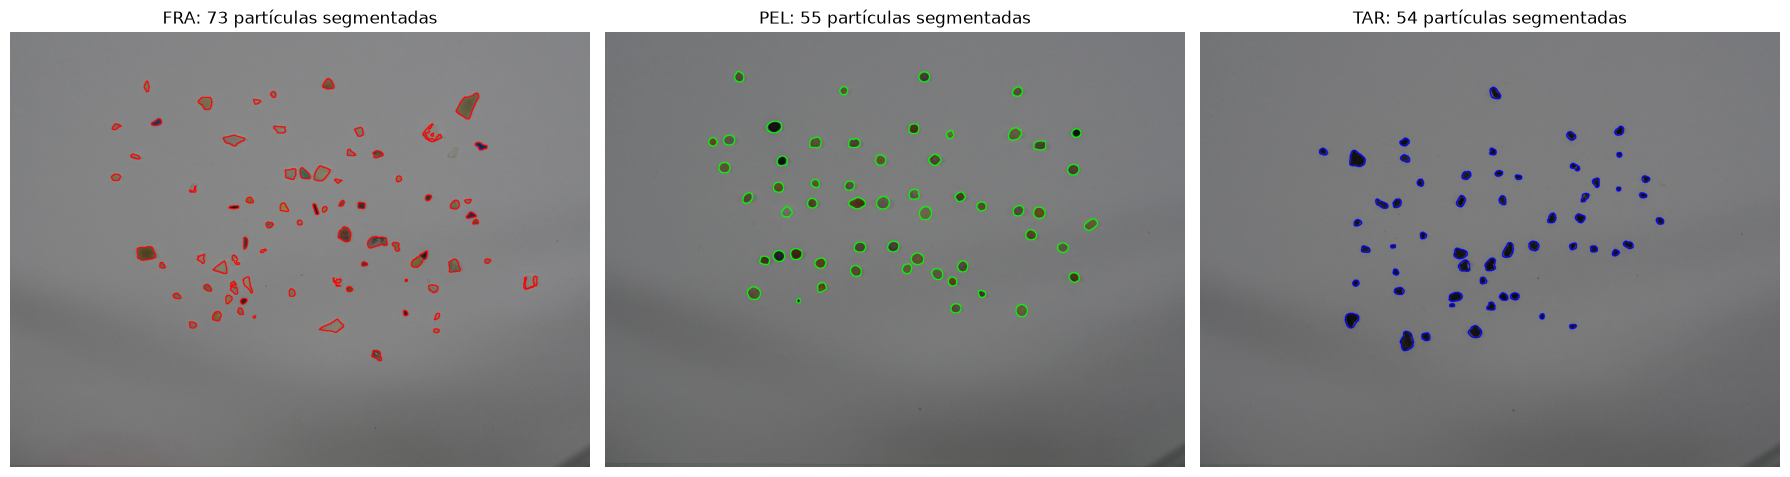

Muestras de entrenamiento por clase: {'FRA': 73, 'PEL': 55, 'TAR': 54}


clase                       FRA     PEL     TAR
area               mean  418.79  639.86  433.45
                   std   406.54  181.42  290.70
perimetro          mean   83.88   94.88   77.73
                   std    43.32   14.81   25.25
compacidad         mean   21.21   14.41   15.19
                   std    15.76    0.44    0.99
area/contenedor    mean    0.60    0.72    0.67
                   std     0.11    0.04    0.04
ancho/alto         mean    0.80    0.93    0.86
                   std     0.16    0.06    0.10
rel_ejes_elipse    mean    0.68    0.88    0.76
                   std     0.17    0.08    0.13
rel_dist_centroide mean    0.48    0.79    0.63
                   std     0.18    0.08    0.11
solidez            mean    0.91    0.98    0.97
                   std     0.12    0.01    0.01
dif_l              mean  -31.02  -46.11  -77.40
                   std    19.00   14.38    6.91
dif_a              mean   -0.86    1.49    0.69
                   std     3.15    2.37    0.28
dif_b              mean    7.10   10.57   -0.48
                   std     7.18    5.04    0.70
croma              mean    9.20   10.96    1.02
                   std     5.25    4.98    0.48
dsv_l              mean   13.71   16.61   40.53
                   std    11.49    8.55    2.59


Partículas anotadas en el CSV: 120
Partículas detectadas por la segmentación: 120
Emparejadas (IoU >= 0.3), se usan para evaluar: 110
Anotadas que no se detectaron: 10
Detectadas que no corresponden a ninguna anotación: 10

k-NN (k=5)
Exactitud: 81.8%
Precisión: 83.3%
Exhaustividad: 81.8%
Valor F1: 81.1%


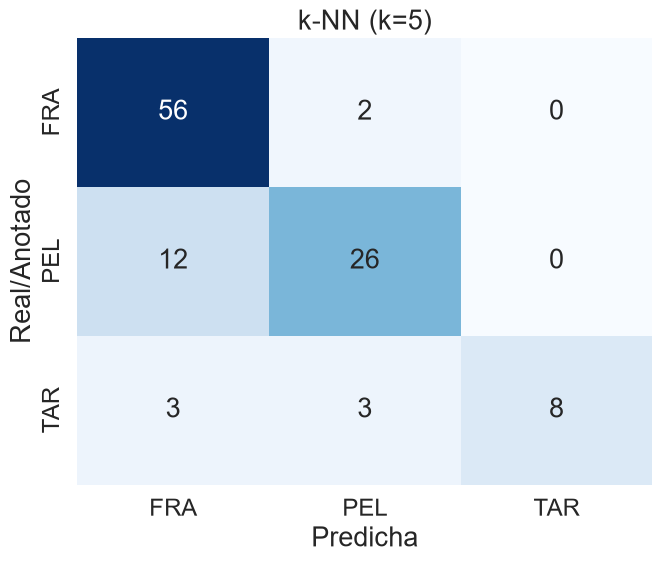

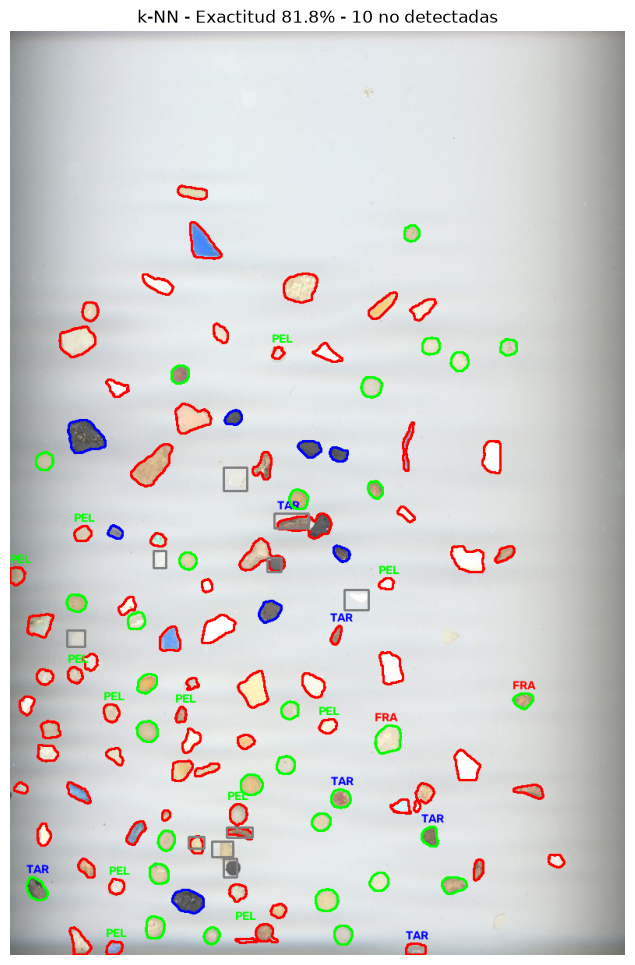

In [4]:
# Se reduce la resolución de las imágenes de entrenamiento para que el área mediana de sus partículas coincida con la de la imagen de prueba.
areas_entrena = np.concatenate([procesar_imagen(ruta, area_min=80, quitar_borde=True)[2][:, 0]
                                for ruta in (img_fra, img_pel, img_tar)])
areas_prueba = procesar_imagen(img_test_ruta)[2][:, 0]
escala_entrena = np.sqrt(np.median(areas_prueba) / np.median(areas_entrena))


# ENTRENAMIENTO
# Cada imagen contiene una sola clase, así que todas sus partículas reciben esa etiqueta.
lista_carac, lista_etiquetas = [], []
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))      # una figura con 3 huecos, uno por imagen
for eje, (ruta, clase) in zip(ejes, [(img_fra, 'FRA'), (img_pel, 'PEL'), (img_tar, 'TAR')]):
    # Reescala la imagen, la segmenta y calcula las características de sus partículas
    img, contornos, carac = procesar_imagen(ruta, escala=escala_entrena, quitar_borde=True)
    lista_carac.append(carac)
    lista_etiquetas += [clase] * len(carac)          # una etiqueta por cada partícula de la imagen

    # Dibuja los contornos segmentados para comprobar la segmentación de las imágenes de entrenamiento
    img_resultado = img.copy()
    cv2.drawContours(img_resultado, contornos, -1, colores[clase], 2)
    eje.imshow(cv2.cvtColor(img_resultado, cv2.COLOR_BGR2RGB))
    eje.set_title(f'{clase}: {len(contornos)} partículas segmentadas')
    eje.axis('off')
plt.tight_layout()
plt.show()

# Junta las partículas de las tres imágenes en una sola matriz y un solo vector de etiquetas
carac_entrena = np.vstack(lista_carac)          # una fila por partícula, una columna por característica
etiquetas_entrena = np.array(lista_etiquetas)   # clase de cada partícula
print('Muestras de entrenamiento por clase:',
      {clase: int((etiquetas_entrena == clase).sum()) for clase in clases})

# Características usadas para clasificar
indices_carac = [nombres_carac.index(nombre) for nombre in nombres_carac]   # posición de cada una en la matriz


# Media y desviación de cada característica por clase
datos = pd.DataFrame(carac_entrena, columns=nombres_carac)
datos['clase'] = etiquetas_entrena
tabla = datos.groupby('clase').agg(['mean', 'std']).round(2).T   # agrupa por clase y calcula media y desviación
display(tabla)


# ENTRENAMIENTO DEL CLASIFICADOR 
# k-NN (k=5): cada partícula recibe la clase mayoritaria de sus 5 vecinas más parecidas.
# StandardScaler normaliza las características para que todas pesen igual.
modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo.fit(carac_entrena[:, indices_carac], etiquetas_entrena)


# PRUEBA: DETECCIÓN Y COMPARACIÓN CON EL CSV
# Lee las anotaciones del CSV
anotaciones = []
with open(csv_test, newline='') as archivo:
    for fila in csv.DictReader(archivo):
        anotaciones.append((fila['label'], *map(int, [fila['x_min'], fila['y_min'],
                                                      fila['x_max'], fila['y_max']])))

# Segmenta la imagen de prueba
img_prueba, contornos_prueba, carac_prueba = procesar_imagen(img_test_ruta)

# Obtiene la caja de cada partícula detectada en formato (x_min, y_min, x_max, y_max)
cajas_prueba = []
for contorno in contornos_prueba:
    x, y, w, h = cv2.boundingRect(contorno)
    cajas_prueba.append((x, y, x + w, y + h))

# Empareja cada anotación con la detección de mayor IoU
pares = sorted(((iou(anotacion[1:], caja), i_anot, i_det)
                for i_anot, anotacion in enumerate(anotaciones)
                for i_det, caja in enumerate(cajas_prueba)), reverse=True)
anot_asignadas, det_asignadas, emparejados = set(), set(), []
for solape, i_anot, i_det in pares:
    if solape < umbral_iou:
        break
    if i_anot not in anot_asignadas and i_det not in det_asignadas:
        anot_asignadas.add(i_anot)
        det_asignadas.add(i_det)
        emparejados.append((i_anot, i_det))
emparejados.sort()

print(f'\nPartículas anotadas en el CSV: {len(anotaciones)}')
print(f'Partículas detectadas por la segmentación: {len(contornos_prueba)}')
print(f'Emparejadas (IoU >= {umbral_iou}), se usan para evaluar: {len(emparejados)}')
print(f'Anotadas que no se detectaron: {len(anotaciones) - len(emparejados)}')
print(f'Detectadas que no corresponden a ninguna anotación: {len(contornos_prueba) - len(emparejados)}')

# Clase real (del CSV) y características de las partículas emparejadas
clases_reales = [anotaciones[i_anot][0] for i_anot, _ in emparejados]
carac_emparejadas = carac_prueba[[i_det for _, i_det in emparejados]][:, indices_carac]

# CLASIFICACIÓN Y RESULTADOS
clases_predichas = modelo.predict(carac_emparejadas)
no_detectadas = len(anotaciones) - len(emparejados)

exactitud = mostrar_metricas(clases_reales, clases_predichas, 'k-NN (k=5)')
mostrar_matriz_confusion(clases_reales, clases_predichas, 'k-NN (k=5)')
mostrar_resultado(img_prueba, contornos_prueba, anotaciones, emparejados, clases_predichas,
                  f'k-NN - Exactitud {exactitud:.1%} - {no_detectadas} no detectadas')


Árbol de decisión (profundidad 2)
Exactitud: 76.4%
Precisión: 77.3%
Exhaustividad: 76.4%
Valor F1: 75.7%


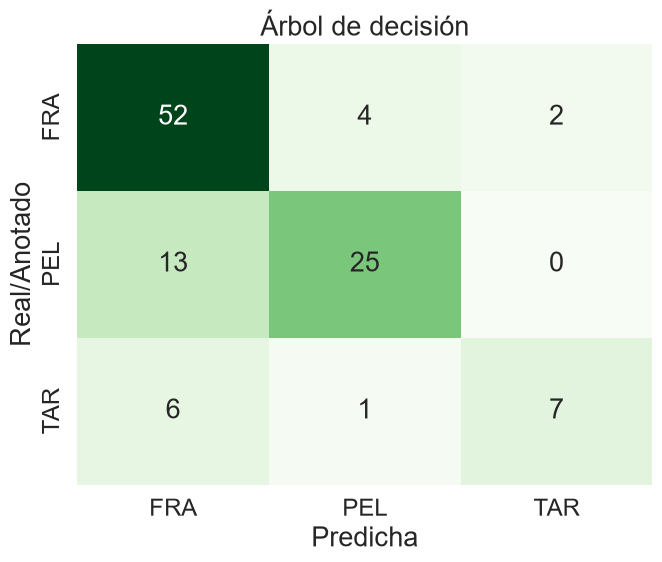

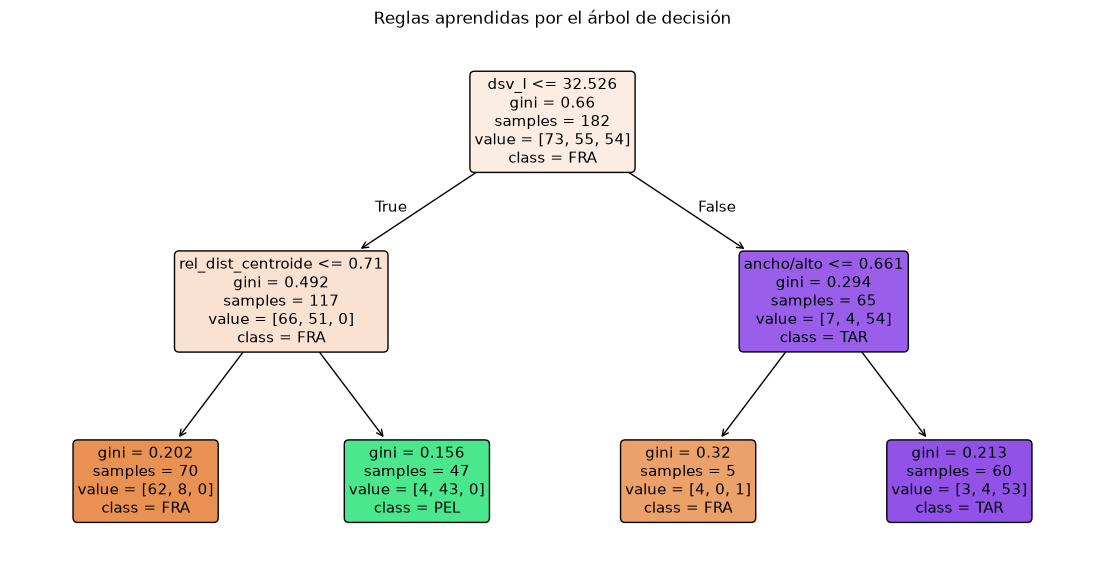

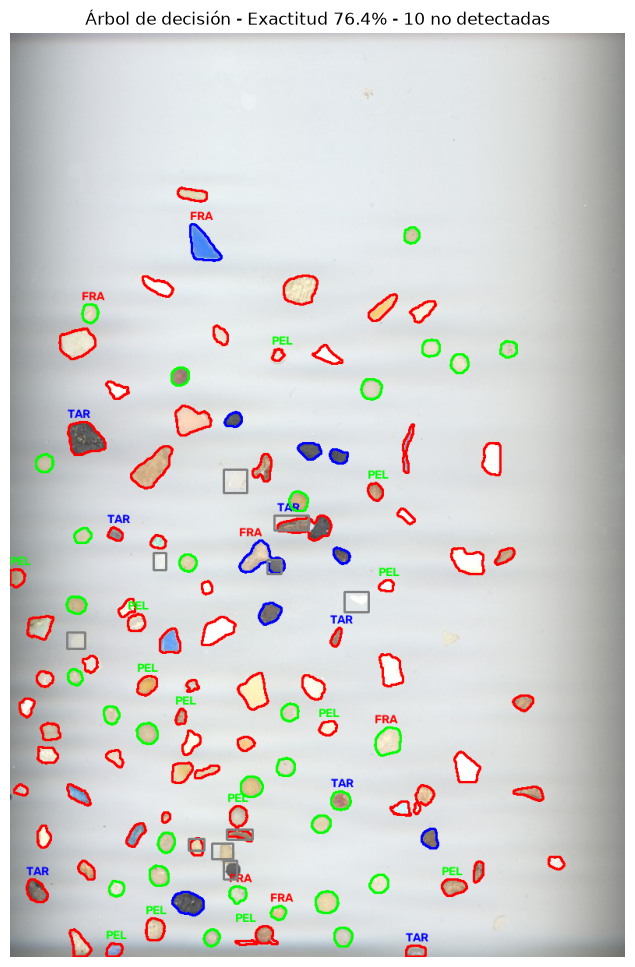

In [ ]:
# EXTRA: CLASIFICADOR CON UN ÁRBOL DE DECISIÓN
# Aprende reglas sencillas del tipo "si característica <= umbral" y permite ver cómo decide.
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Árbol de profundidad 2: como mucho dos preguntas por partícula (no necesita normalizar, porque cada regla compara una sola característica con un umbral)
arbol = DecisionTreeClassifier(max_depth=2, random_state=0)
arbol.fit(carac_entrena[:, indices_carac], etiquetas_entrena)

# Clasificación de las partículas emparejadas de la imagen de prueba
clases_predichas_arbol = arbol.predict(carac_emparejadas)

# Métricas, matriz de confusión (mismas funciones que con k-NN)
exactitud_arbol = mostrar_metricas(clases_reales, clases_predichas_arbol, 'Árbol de decisión (profundidad 2)')
mostrar_matriz_confusion(clases_reales, clases_predichas_arbol, 'Árbol de decisión', mapa_color='Greens')

# Dibujo del árbol: cada caja muestra la regla, el número de partículas y la clase mayoritaria
plt.figure(figsize=(14, 7))
plot_tree(arbol, feature_names=[nombres_carac[i] for i in indices_carac],
          class_names=list(arbol.classes_), filled=True, rounded=True, fontsize=11)
plt.title("Reglas aprendidas por el árbol de decisión")
plt.show()

# Imagen de resultados del árbol sobre la imagen de prueba
mostrar_resultado(img_prueba, contornos_prueba, anotaciones, emparejados, clases_predichas_arbol,
                  f'Árbol de decisión - Exactitud {exactitud_arbol:.1%} - {no_detectadas} no detectadas')